# Practical 6: Statistical Tests

**Dataset:** TeachingRatings.csv

**Aim:** Apply a t-test, ANOVA, chi-square test and correlation test at a 5% significance level.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ratings = pd.read_csv("TeachingRatings.csv")
alpha = 0.05
print(ratings.shape)

(463, 13)


### Test 1: t-test, does gender affect evaluation score?

H0: mean evaluation is the same for men and women. H1: the means are different.

In [2]:
men = ratings.loc[ratings["gender"] == "male", "eval"]
women = ratings.loc[ratings["gender"] == "female", "eval"]
t_value, p_t = stats.ttest_ind(men, women, equal_var=False)
print("Male mean   :", round(men.mean(), 4), "n =", len(men))
print("Female mean :", round(women.mean(), 4), "n =", len(women))
print("t-statistic :", round(t_value, 4))
print("p-value     :", round(p_t, 4))
verdict_t = "reject H0" if p_t < alpha else "fail to reject H0"
print("Decision    :", verdict_t)

Male mean   : 4.069 n = 268
Female mean : 3.901 n = 195
t-statistic : 3.2667
p-value     : 0.0012
Decision    : reject H0


**Result:** Men average 4.0690 and women average 3.9010. The p-value 0.0012 is below 0.05, so we reject H0. Gender has a significant effect on evaluation scores in this data.

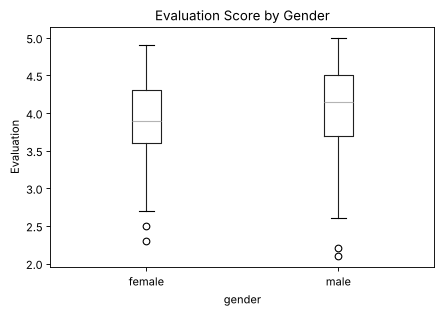

In [3]:
ratings.boxplot(column="eval", by="gender", figsize=(6, 4), grid=False)
plt.title("Evaluation Score by Gender")
plt.suptitle("")
plt.ylabel("Evaluation")
plt.show()

### Test 2: ANOVA, does beauty score differ by age group?

H0: mean beauty score is the same in all age groups. H1: at least one group differs.

In [4]:
ratings["age_group"] = pd.qcut(ratings["age"], 4, labels=["Group 1 (youngest)", "Group 2", "Group 3", "Group 4 (oldest)"])
group_table = ratings.groupby("age_group", observed=True)["beauty"].agg(["count", "mean"]).round(4)
print(group_table)
samples = [part["beauty"] for _, part in ratings.groupby("age_group", observed=True)]
f_value, p_f = stats.f_oneway(*samples)
print("F-statistic :", round(f_value, 4))
print("p-value     :", p_f)
verdict_f = "reject H0" if p_f < alpha else "fail to reject H0"
print("Decision    :", verdict_f)

                    count    mean
age_group                        
Group 1 (youngest)    136  0.3426
Group 2                97 -0.1051
Group 3               136 -0.1049
Group 4 (oldest)       94 -0.2354
F-statistic : 13.782
p-value     : 1.2756053142266569e-08
Decision    : reject H0


**Result:** F = 13.7820 and the p-value is 1.28e-08, which is below 0.05, so we reject H0. Beauty scores differ significantly across age groups, and the youngest group has the highest average.

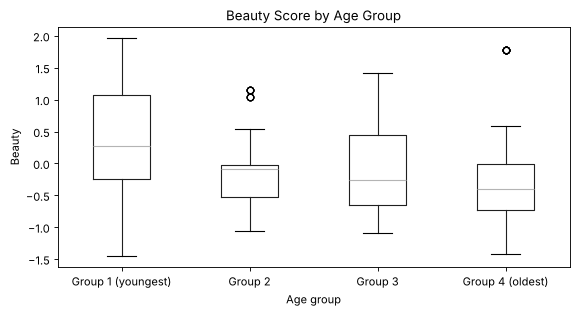

In [5]:
ratings.boxplot(column="beauty", by="age_group", figsize=(8, 4), grid=False)
plt.title("Beauty Score by Age Group")
plt.suptitle("")
plt.xlabel("Age group")
plt.ylabel("Beauty")
plt.show()

### Test 3: Chi-square test, are tenure and gender associated?

H0: tenure and gender are independent. H1: they are associated.

In [6]:
table = pd.crosstab(ratings["gender"], ratings["tenure"])
chi, p_c, dof, expected = stats.chi2_contingency(table)
print(table)
print("Chi-square  :", round(chi, 4))
print("Degrees of freedom:", dof)
print("p-value     :", round(p_c, 4))
verdict_c = "reject H0" if p_c < alpha else "fail to reject H0"
print("Decision    :", verdict_c)

tenure  no  yes
gender         
female  50  145
male    52  216
Chi-square  : 2.2068
Degrees of freedom: 1
p-value     : 0.1374
Decision    : fail to reject H0


**Result:** Chi-square = 2.2068 with 1 degree of freedom and p-value 0.1374, which is above 0.05, so we fail to reject H0. No significant association between tenure and gender was found.

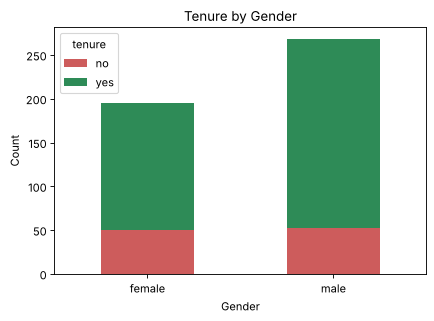

In [7]:
table.plot(kind="bar", stacked=True, figsize=(6, 4), color=["indianred", "seagreen"])
plt.title("Tenure by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Test 4: Correlation, is evaluation related to beauty score?

H0: the correlation is zero. H1: the correlation is not zero.

In [8]:
r_value, p_r = stats.pearsonr(ratings["eval"], ratings["beauty"])
print("Pearson r :", round(r_value, 4))
print("p-value   :", p_r)
verdict_r = "reject H0" if p_r < alpha else "fail to reject H0"
print("Decision  :", verdict_r)

Pearson r : 0.189
p-value   : 4.247115507785999e-05
Decision  : reject H0


**Result:** r = 0.1890 and the p-value 4.25e-05 is below 0.05, so we reject H0. There is a significant but very weak positive correlation between beauty score and evaluation score.

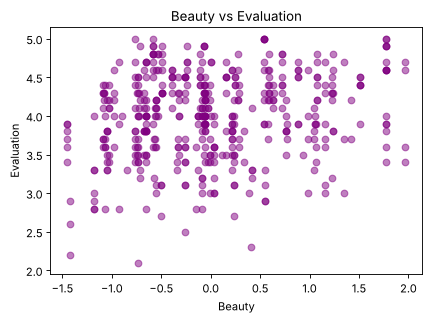

In [9]:
plt.figure(figsize=(6, 4))
plt.scatter(ratings["beauty"], ratings["eval"], color="purple", alpha=0.5)
plt.title("Beauty vs Evaluation")
plt.xlabel("Beauty")
plt.ylabel("Evaluation")
plt.show()